In [3]:
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays, JSON
using Colors, Dates
using CSV
using DataFrames

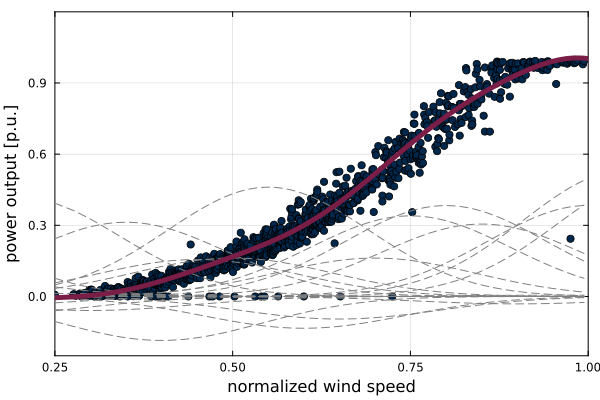


========== MODEL PERFORMANCE ==========
RMSE = 0.058834962209225065
MAE  = 0.03543028988092969


In [4]:
# RBF-SVM for wind power curve fitting with Tikhonov regularization, wind power data example from ECE 598

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)
dataset = JSON.parsefile("wind_power_data.json")
n = length(dataset["ActivePower"])
sort_index = sortperm(dataset["WindSpeed"])
t = Float64.(dataset["ActivePower"][sort_index])
x_raw = Float64.(dataset["WindSpeed"][sort_index])
x = x_raw ./ 10.0

# Parameters
α = 0.01          # learning rate
iter_max = 25_000 # maximum iterations
λ = 0.001         # regularization coefficient
reg_type = "l2"
c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

# Gaussian RBF
function φ(x, j)
    return exp(-(γ * abs(x - c[j]))^2)
end

Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x[i], j)
    end
end

Random.seed!(128)
w_0 = rand()
w = rand(num_centers)

# Stochastic Gradient Descent
for iteration in 1:iter_max

    i = rand(1:n)
    ϕi = Φ[i, :]
    y_hat = w_0 + dot(ϕi, w)
    error = y_hat - t[i]
    w_0 -= α * error
    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end

    if reg_type == "l2"
        w .-= α * λ .* w
    elseif reg_type == "l1"
        w .= sign.(w) .* max.(0, abs.(w) .- α * λ)

    end

end

function w̅(x_value)
    return w_0 + sum(w[j] * φ(x_value, j)
                     for j in 1:num_centers)
end

prediction = w_0 .+ Φ * w

plo = scatter(x,t,c = blue,frame = :box,label = false,xlabel = "normalized wind speed",ylabel = "power output [p.u.]")
plot!(plo,ylims = (-0.25, 1.2),xlims = (0.25, 1.0))

for j in 1:num_centers
    plot!(plo,x,w[j] .* Φ[:, j],c = :gray,label = false,linestyle = :dash)
end

plot!(plo,x,fill(w_0, length(x)),c = :gray,label = false,linestyle = :dash)
plot!(plo,w̅,0.25,1.0,lw = 5,c = purple,label = false)

display(plo)

errors = prediction .- t

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("=======================================")

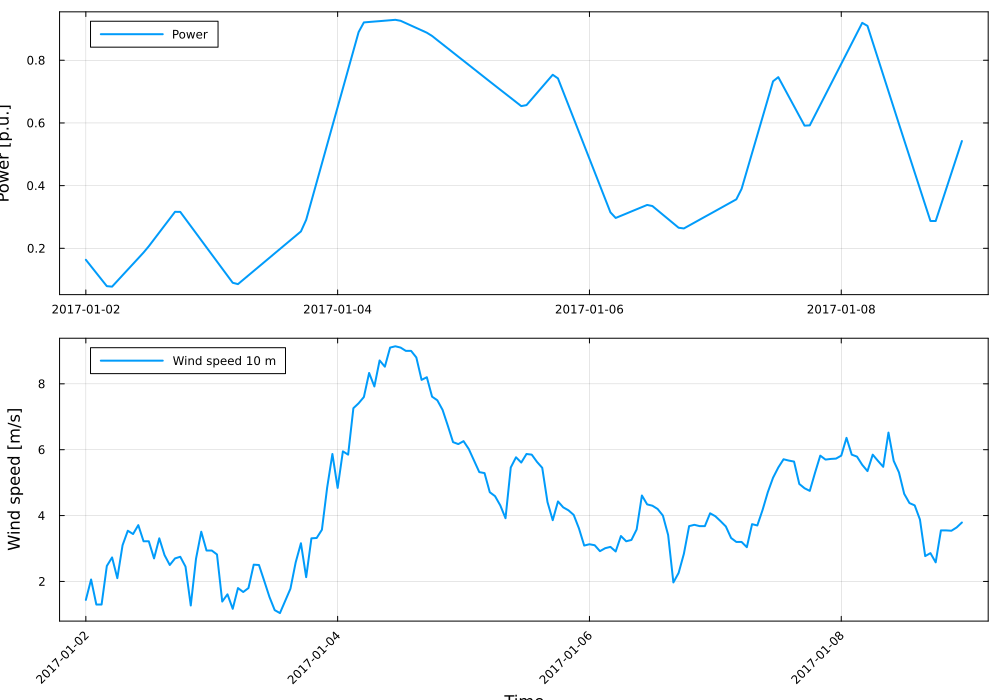

In [8]:
data = CSV.read("Location1.csv", DataFrame)
data.Time = DateTime.(data.Time)

n_week = min(168, nrow(data))

time_week = data.Time[1:n_week]
power_week = Float64.(data.Power[1:n_week])
wind10_week = Float64.(data.windspeed_10m[1:n_week])

p1 = plot(time_week,power_week,lw=2,label="Power",xlabel="",ylabel="Power [p.u.]",frame=:box,legend=:topleft)
p2 = plot(time_week,wind10_week,lw=2,label="Wind speed 10 m",xlabel="Time",ylabel="Wind speed [m/s]",xrotation=45,frame=:box,legend=:topleft)

display(plot(p1,p2,layout=(2,1),size=(1000,700)))

In [ ]:
# RBF-SVM for wind power curve fitting with Tikhonov regularization

# Data read from Location1.csv and organized chronologically

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

data = CSV.read("Location1.csv", DataFrame)
n = nrow(data)
data.Time = DateTime.(data.Time)
sort_index = sortperm(data.Time)
t = Float64.(data.Power[sort_index])
wind10_raw = Float64.(data.windspeed_10m[sort_index])
time = data.Time[sort_index]
x = wind10_raw ./ 10.0
hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

43800-element Vector{Float64}:
  1.0
  0.9659258262890683
  0.8660254037844387
  0.7071067811865476
  0.5000000000000001
  0.25881904510252074
  6.123233995736766e-17
 -0.25881904510252063
 -0.4999999999999998
 -0.7071067811865475
  ⋮
 -0.7071067811865479
 -0.5000000000000004
 -0.25881904510252063
 -1.8369701987210297e-16
  0.2588190451025203
  0.5000000000000001
  0.7071067811865474
  0.8660254037844384
  0.9659258262890681

In [ ]:
# RBF-SVM for wind power curve fitting with Tikhonov regularization

# Learning Algorithm 

# Parameters
α = 0.01          # learning rate
iter_max = 25_000 # maximum iterations
λ = 0.01         # regularization coefficient
reg_type = "l2"

# RBF centers
c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

function φ(x, j)
    return exp(-(γ * abs(x - c[j]))^2)
end

Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x[i], j)
    end
end

Random.seed!(128)
w_0 = rand()
w = rand(num_centers)

# Stochastic Gradient Descent
for iteration in 1:iter_max

    i = rand(1:n)
    ϕi = Φ[i, :]
    y_hat = w_0 + dot(ϕi, w)
    error = y_hat - t[i]
    w_0 -= α * error
    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end
    # Regularization
    if reg_type == "l2"

        w .-= α * λ .* w

    elseif reg_type == "l1"

        w .= sign.(w) .* max.(0, abs.(w) .- α * λ)

    end

end


prediction = w_0 .+ Φ * w

errors = prediction .- t



========== MODEL PERFORMANCE ==========
RMSE = 0.19076245851835608
MAE  = 0.1485094314115183


In [6]:
# RBF-SVM for wind power curve fitting with Tikhonov regularization

#Method evalutation

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("=======================================")


========== MODEL PERFORMANCE ==========
RMSE = 0.19076245851835608
MAE  = 0.1485094314115183


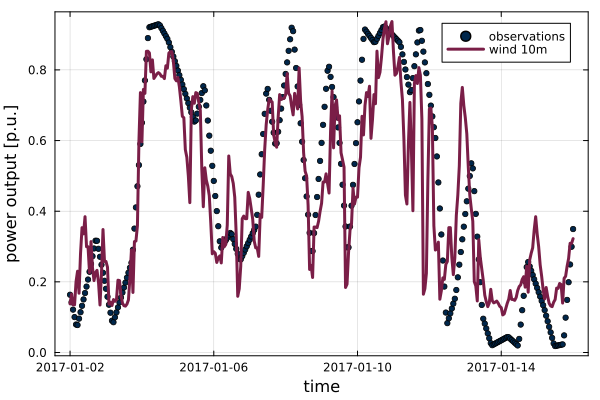

In [27]:
two_weeks = time .<= (time[1] + Day(14))
time_2wk = time[two_weeks]
t_2wk = t[two_weeks]
prediction_2wk = prediction[two_weeks]

plo = scatter(time_2wk,t_2wk,c=blue,frame=:box,label="observations",xlabel="time",ylabel="power output [p.u.]",markersize=3)
plot!(plo,time_2wk,prediction_2wk,lw=3,c=purple,label="wind 10m")

display(plo)

In [39]:
# =========================================================
# Hyperparameter search for optimal γ and λ
# =========================================================

# Hyperparameter ranges
γ_values = [0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 5.5, 6.0, 8.0, 10.0, 15.0, 20.0]
λ_values = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

# ---------------------------------------------------------
# Chronological train / validation split
# ---------------------------------------------------------

train_fraction = 0.8
n_train = floor(Int, train_fraction * n)

train_idx = 1:n_train
val_idx = (n_train + 1):n

x_train = x[train_idx]
t_train = t[train_idx]

x_val = x[val_idx]
t_val = t[val_idx]

# ---------------------------------------------------------
# Store results
# ---------------------------------------------------------

best_RMSE = Inf
best_γ = nothing
best_λ = nothing

results = []

# ---------------------------------------------------------
# Grid search
# ---------------------------------------------------------

for γ_test in γ_values

    # RBF matrix for training data
    Φ_train = zeros(length(x_train), num_centers)

    for i in 1:length(x_train)
        for j in 1:num_centers
            Φ_train[i, j] =
                exp(-(γ_test * abs(x_train[i] - c[j]))^2)
        end
    end

    # RBF matrix for validation data
    Φ_val = zeros(length(x_val), num_centers)

    for i in 1:length(x_val)
        for j in 1:num_centers
            Φ_val[i, j] =
                exp(-(γ_test * abs(x_val[i] - c[j]))^2)
        end
    end

    for λ_test in λ_values

        # -------------------------------------------------
        # Initialize weights
        # -------------------------------------------------

        Random.seed!(128)

        w_0_test = rand()
        w_test = rand(num_centers)

        # -------------------------------------------------
        # SGD
        # -------------------------------------------------

        for iteration in 1:iter_max

            i = rand(1:length(x_train))

            ϕi = Φ_train[i, :]

            y_hat = w_0_test + dot(ϕi, w_test)

            error = y_hat - t_train[i]

            w_0_test -= α * error

            for j in 1:num_centers
                w_test[j] -= α * error * ϕi[j]
            end

            # L2 Tikhonov regularization
            if reg_type == "l2"
                w_test .-= α * λ_test .* w_test

            elseif reg_type == "l1"
                w_test .= sign.(w_test) .* max.(
                    0,
                    abs.(w_test) .- α * λ_test
                )
            end

        end

        # -------------------------------------------------
        # Validation prediction
        # -------------------------------------------------

        prediction_val = w_0_test .+ Φ_val * w_test

        errors_val = prediction_val .- t_val

        RMSE_val = sqrt(mean(errors_val.^2))

        push!(results, (γ_test, λ_test, RMSE_val))

        println(
            "γ = ", γ_test,
            " | λ = ", λ_test,
            " | Validation RMSE = ", RMSE_val
        )

        # -------------------------------------------------
        # Track best hyperparameters
        # -------------------------------------------------

        if RMSE_val < best_RMSE

            best_RMSE = RMSE_val
            best_γ = γ_test
            best_λ = λ_test

        end

    end
end

# =========================================================
# Optimal hyperparameters
# =========================================================

println()
println("============================================")
println("       OPTIMAL HYPERPARAMETERS")
println("============================================")
println("Best γ = ", best_γ)
println("Best λ = ", best_λ)
println("Best validation RMSE = ", best_RMSE)
println("============================================")

γ = 0.5 | λ = 1.0e-5 | Validation RMSE = 0.23986331843665082
γ = 0.5 | λ = 0.0001 | Validation RMSE = 0.2395363557789627
γ = 0.5 | λ = 0.001 | Validation RMSE = 0.2367684061394217
γ = 0.5 | λ = 0.01 | Validation RMSE = 0.23399230767856632
γ = 0.5 | λ = 0.1 | Validation RMSE = 0.27608663811807904
γ = 1.0 | λ = 1.0e-5 | Validation RMSE = 0.2268438599232318
γ = 1.0 | λ = 0.0001 | Validation RMSE = 0.2267522431976255
γ = 1.0 | λ = 0.001 | Validation RMSE = 0.2259370196227261
γ = 1.0 | λ = 0.01 | Validation RMSE = 0.2226523965251334
γ = 1.0 | λ = 0.1 | Validation RMSE = 0.22725601076830715
γ = 2.0 | λ = 1.0e-5 | Validation RMSE = 0.20723289397435907
γ = 2.0 | λ = 0.0001 | Validation RMSE = 0.20716671114445498
γ = 2.0 | λ = 0.001 | Validation RMSE = 0.20658354210774182
γ = 2.0 | λ = 0.01 | Validation RMSE = 0.20450248599988397
γ = 2.0 | λ = 0.1 | Validation RMSE = 0.20873852912256186
γ = 3.0 | λ = 1.0e-5 | Validation RMSE = 0.19780644573477016
γ = 3.0 | λ = 0.0001 | Validation RMSE = 0.19780

In [ ]:
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays
using Colors
using CSV, DataFrames, Dates

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

data = CSV.read("Location1.csv", DataFrame)
n = nrow(data)
data.Time = DateTime.(data.Time)
sort_index = sortperm(data.Time)
t = Float64.(data.Power[sort_index])

wind10_raw = Float64.(data.windspeed_10m[sort_index])
wind100_raw = Float64.(data.windspeed_100m[sort_index])   
time = data.Time[sort_index]

x10 = wind10_raw ./ 10.0
x100 = wind100_raw ./ 10.0   

hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

α = 0.01
iter_max = 25_000
λ = 0.01
reg_type = "l2"

c = collect(0.0:0.05:1.1)

centers = [(c[i], c[j]) for i in 1:length(c), j in 1:length(c)]   
centers = vec(centers)   
num_centers = length(centers)   
γ = 5.0

function φ(x10, x100, j)   
    c10, c100 = centers[j]   
    return exp(-γ * ((x10 - c10)^2 + (x100 - c100)^2))   
end

Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x10[i], x100[i], j)   
    end
end

Random.seed!(128)
w_0 = rand()
w = rand(num_centers)

for iteration in 1:iter_max

    i = rand(1:n)
    ϕi = Φ[i, :]
    y_hat = w_0 + dot(ϕi, w)
    error = y_hat - t[i]

    w_0 -= α * error

    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end

    if reg_type == "l2"

        w .-= α * λ .* w

    elseif reg_type == "l1"

        w .= sign.(w) .* max.(0, abs.(w) .- α * λ)

    end

end

prediction = w_0 .+ Φ * w

errors = prediction .- t

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("=======================================")


========== MODEL PERFORMANCE ==========
RMSE = 0.2311932862691112
MAE  = 0.1930909967034358


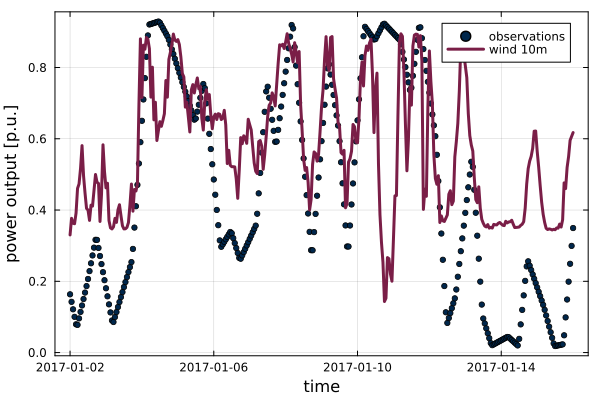

In [42]:
two_weeks = time .<= (time[1] + Day(14))
time_2wk = time[two_weeks]
t_2wk = t[two_weeks]
prediction_2wk = prediction[two_weeks]

plo = scatter(time_2wk,t_2wk,c=blue,frame=:box,label="observations",xlabel="time",ylabel="power output [p.u.]",markersize=3)
plot!(plo,time_2wk,prediction_2wk,lw=3,c=purple,label="wind 10m")

display(plo)

In [ ]:
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays
using Colors
using CSV, DataFrames, Dates

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

data = CSV.read("Location1.csv", DataFrame)
n = nrow(data)
data.Time = DateTime.(data.Time)
sort_index = sortperm(data.Time)
t = Float64.(data.Power[sort_index])

wind10_raw = Float64.(data.windspeed_10m[sort_index])
wind100_raw = Float64.(data.windspeed_100m[sort_index])

time = data.Time[sort_index]

x = wind10_raw ./ 10.0
z = wind100_raw ./ 10.0

hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

α = 0.01
iter_max = 25_000
λ = 0.01
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

function φ(x, j)
    return exp(-(γ * abs(x - c[j]))^2)
end

Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x[i], j)
    end
end

Random.seed!(128)
w_0 = rand()
w = rand(num_centers)
β_100 = rand()

for iteration in 1:iter_max

    i = rand(1:n)
    ϕi = Φ[i, :]

    y_hat = w_0 + dot(ϕi, w) + β_100 * z[i]

    error = y_hat - t[i]

    w_0 -= α * error

    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end

    β_100 -= α * error * z[i]

    if reg_type == "l2"

        w .-= α * λ .* w
        β_100 -= α * λ * β_100

    elseif reg_type == "l1"

        w .= sign.(w) .* max.(0, abs.(w) .- α * λ)
        β_100 = sign(β_100) * max(0, abs(β_100) - α * λ) 

    end

end

prediction = w_0 .+ Φ * w .+ β_100 .* z 

errors = prediction .- t

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("β_100 = ", β_100)
println("=======================================")


========== MODEL PERFORMANCE ==========
RMSE = 0.17567395918832002
MAE  = 0.13573263169683555
β_100 = 0.4567642161173134


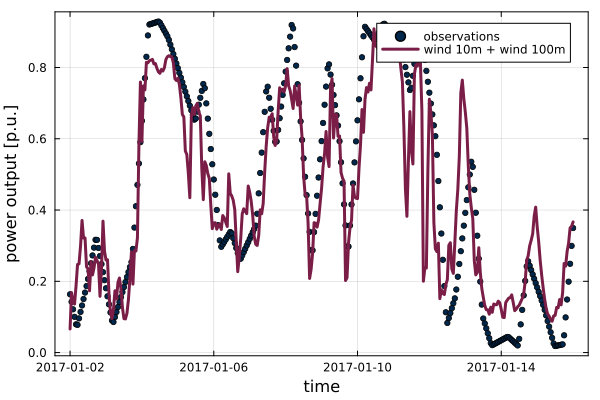

In [48]:
two_weeks = time .<= (time[1] + Day(14))
time_2wk = time[two_weeks]
t_2wk = t[two_weeks]
prediction_2wk = prediction[two_weeks]

plo = scatter(time_2wk,t_2wk,c=blue,frame=:box,label="observations",xlabel="time",ylabel="power output [p.u.]",markersize=3)
plot!(plo,time_2wk,prediction_2wk,lw=3,c=purple,label="wind 10m + wind 100m")

display(plo)

In [ ]:
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays
using Colors
using CSV, DataFrames, Dates

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

data = CSV.read("Location1.csv", DataFrame)
n = nrow(data)
data.Time = DateTime.(data.Time)
sort_index = sortperm(data.Time)

t = Float64.(data.Power[sort_index])

wind10_raw = Float64.(data.windspeed_10m[sort_index])
wind100_raw = Float64.(data.windspeed_100m[sort_index])
windgust_raw = Float64.(data.windgusts_10m[sort_index])  

time = data.Time[sort_index]

x = wind10_raw ./ 10.0
z = wind100_raw ./ 10.0
windgust = windgust_raw ./ 10.0  

hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

α = 0.01
iter_max = 25_000
λ = 0.01
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

function φ(x, j)
    return exp(-(γ * abs(x - c[j]))^2)
end

Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x[i], j)
    end
end

Random.seed!(128)
w_0 = rand()
w = rand(num_centers)

β_100 = rand()
β_windgust = rand()  

for iteration in 1:iter_max

    i = rand(1:n)
    ϕi = Φ[i, :]

    y_hat = w_0 +
            dot(ϕi, w) +
            β_100 * z[i] +
            β_windgust * windgust[i]  

    error = y_hat - t[i]

    w_0 -= α * error

    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end

    β_100 -= α * error * z[i]
    β_windgust -= α * error * windgust[i]  

    if reg_type == "l2"

        w .-= α * λ .* w
        β_100 -= α * λ * β_100
        β_windgust -= α * λ * β_windgust  

    elseif reg_type == "l1"

        w .= sign.(w) .* max.(0, abs.(w) .- α * λ)
        β_100 = sign(β_100) * max(0, abs(β_100) - α * λ)
        β_windgust = sign(β_windgust) * max(0, abs(β_windgust) - α * λ)

    end

end

function w̅(x_value, z_value, windgust_value)  

    return w_0 +
           sum(w[j] * φ(x_value, j) for j in 1:num_centers) +
           β_100 * z_value +
           β_windgust * windgust_value  

end

prediction = w_0 .+
             Φ * w .+
             β_100 .* z .+
             β_windgust .* windgust  

errors = prediction .- t

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("β_100 = ", β_100)
println("β_windgust = ", β_windgust)  
println("=======================================")


========== MODEL PERFORMANCE ==========
RMSE = 0.17757372150179668
MAE  = 0.13699647306818744
β_100 = 0.44462811111182277
β_windgust = 0.005685496846152606


In [ ]:
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays
using Colors
using CSV, DataFrames, Dates

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load three training datasets
data1 = CSV.read("Location1.csv", DataFrame)   
data2 = CSV.read("Location2.csv", DataFrame)  # ADDED
data3 = CSV.read("Location3.csv", DataFrame)  # ADDED

data1.Time = DateTime.(data1.Time)  # ADDED
data2.Time = DateTime.(data2.Time)  # ADDED
data3.Time = DateTime.(data3.Time)  # ADDED

# Combine training datasets
data = vcat(data1, data2, data3)  # ADDED

n = nrow(data)  # CHANGED
sort_index = sortperm(data.Time)  # CHANGED

t = Float64.(data.Power[sort_index])

wind10_raw = Float64.(data.windspeed_10m[sort_index])
wind100_raw = Float64.(data.windspeed_100m[sort_index])
windgust_raw = Float64.(data.windgusts_10m[sort_index])  

time = data.Time[sort_index]

x = wind10_raw ./ 10.0
z = wind100_raw ./ 10.0
windgust = windgust_raw ./ 10.0  

hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

α = 0.01
iter_max = 25_000
λ = 0.01
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

function φ(x, j)
    return exp(-(γ * abs(x - c[j]))^2)
end

Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x[i], j)
    end
end

Random.seed!(128)
w_0 = rand()
w = rand(num_centers)

β_100 = rand()
β_windgust = rand()  

for iteration in 1:iter_max

    i = rand(1:n)
    ϕi = Φ[i, :]

    y_hat = w_0 +
            dot(ϕi, w) +
            β_100 * z[i] +
            β_windgust * windgust[i]  

    error = y_hat - t[i]

    w_0 -= α * error

    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end

    β_100 -= α * error * z[i]
    β_windgust -= α * error * windgust[i]  

    if reg_type == "l2"

        w .-= α * λ .* w
        β_100 -= α * λ * β_100
        β_windgust -= α * λ * β_windgust  

    elseif reg_type == "l1"

        w .= sign.(w) .* max.(0, abs.(w) .- α * λ)
        β_100 = sign(β_100) * max(0, abs(β_100) - α * λ)
        β_windgust = sign(β_windgust) * max(0, abs(β_windgust) - α * λ)

    end

end

function w̅(x_value, z_value, windgust_value)  

    return w_0 +
           sum(w[j] * φ(x_value, j) for j in 1:num_centers) +
           β_100 * z_value +
           β_windgust * windgust_value  

end

prediction = w_0 .+
             Φ * w .+
             β_100 .* z .+
             β_windgust .* windgust  

errors = prediction .- t

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("β_100 = ", β_100)
println("β_windgust = ", β_windgust)  
println("=======================================")


========== MODEL PERFORMANCE ==========
RMSE = 0.21613859159202997
MAE  = 0.1649111671777062
β_100 = 0.37000995237506024
β_windgust = 0.17825860205961466


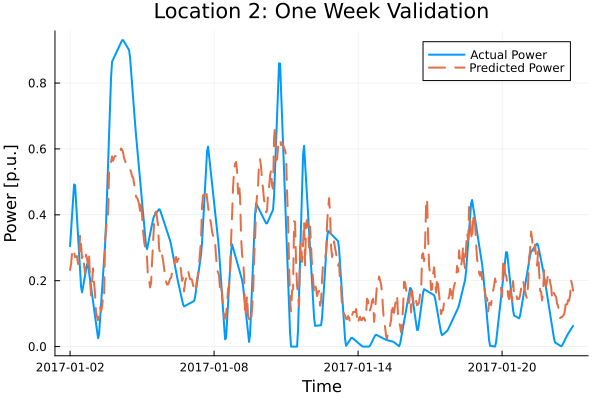


======= VALIDATION PERFORMANCE =======
Validation RMSE = 0.12361830013361927


In [57]:
# Load validation data
validation_data = CSV.read("Location4.csv", DataFrame)  

validation_data.Time = DateTime.(validation_data.Time)  
validation_sort_index = sortperm(validation_data.Time) 
validation_data = validation_data[validation_sort_index, :]  

# Three weeks = 21 days × 24 hours = 504 hours
n_validation = min(504, nrow(validation_data))  

validation_time = validation_data.Time[1:n_validation]  
validation_power = Float64.(validation_data.Power[1:n_validation])  

validation_wind10 = Float64.(validation_data.windspeed_10m[1:n_validation]) ./ 10.0  
validation_wind100 = Float64.(validation_data.windspeed_100m[1:n_validation]) ./ 10.0   
validation_windgust = Float64.(validation_data.windgusts_10m[1:n_validation]) ./ 10.0   

# Create validation RBF matrix
Φ_validation = zeros(n_validation, num_centers)   

for i in 1:n_validation
    for j in 1:num_centers
        Φ_validation[i, j] = φ(validation_wind10[i], j)   
    end
end

# Predict validation data
validation_prediction = w_0 .+
                        Φ_validation * w .+
                        β_100 .* validation_wind100 .+
                        β_windgust .* validation_windgust   

# Calculate validation RMSE
validation_errors = validation_prediction .- validation_power   
validation_RMSE = sqrt(mean(validation_errors.^2))   

println()
println("======= VALIDATION PERFORMANCE =======")
println("Validation RMSE = ", validation_RMSE)
println("=====================================")

# Plot actual vs predicted power
p_validation = plot(validation_time,validation_power,lw=2,label="Actual Power",xlabel="Time",ylabel="Power [p.u.]",title="Location 2: One Week Validation")
plot!(p_validation,validation_time,validation_prediction,lw=2,linestyle=:dash,label="Predicted Power")

display(p_validation)

In [60]:
function predict_24hr(filename)

    # Load forecast data
    forecast_data = CSV.read(filename, DataFrame)

    # Convert and sort by time
    forecast_data.Time = DateTime.(forecast_data.Time)
    sort_index = sortperm(forecast_data.Time)
    forecast_data = forecast_data[sort_index, :]

    # Take up to 24 hours
    n_24hr = min(24, nrow(forecast_data))

    time_24hr = forecast_data.Time[1:n_24hr]

    wind10_24hr = Float64.(
        forecast_data.windspeed_10m[1:n_24hr]
    )

    wind100_24hr = Float64.(
        forecast_data.windspeed_100m[1:n_24hr]
    )

    windgust_24hr = Float64.(
        forecast_data.windgusts_10m[1:n_24hr]
    )

    # Normalize exactly as during training
    x10_24hr = wind10_24hr ./ 10.0
    x100_24hr = wind100_24hr ./ 10.0
    xgust_24hr = windgust_24hr ./ 10.0

    # Generate power predictions
    power_prediction_24hr = [
        w̅(
            x10_24hr[i],
            x100_24hr[i],
            xgust_24hr[i]
        )
        for i in 1:n_24hr
    ]

    predictions = DataFrame(
        Time = time_24hr,
        windspeed_10m = wind10_24hr,
        windspeed_100m = wind100_24hr,
        windgusts_10m = windgust_24hr,
        PredictedPower = power_prediction_24hr
    )

    return predictions
end

predict_24hr (generic function with 1 method)

In [62]:
forecast_power = predict_24hr("Location4.csv")

Row,Time,windspeed_10m,windspeed_100m,windgusts_10m,PredictedPower
,DateTime,Float64,Float64,Float64,Float64
1,2017-01-02T00:00:00,3.21,7.6,5.3,0.232773
2,2017-01-02T01:00:00,3.4,7.92,5.7,0.249786
3,2017-01-02T02:00:00,3.81,8.41,6.4,0.282533
4,2017-01-02T03:00:00,3.7,8.26,6.4,0.275649
5,2017-01-02T04:00:00,3.85,8.5,6.6,0.290032
6,2017-01-02T05:00:00,3.59,8.12,6.5,0.271444
7,2017-01-02T06:00:00,3.73,8.0,6.8,0.273473
8,2017-01-02T07:00:00,4.01,7.91,6.8,0.274735
9,2017-01-02T08:00:00,3.81,7.31,6.9,0.250745
